In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

### Load the Data

In [2]:
df = pd.read_csv('Groceries_dataset.csv')
df.head()

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


In [4]:
df.shape

(38765, 3)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB


In [5]:
df['itemDescription'].nunique()

167

### Form the Baskets

In [9]:
df['basket'] = df['Member_number'].astype(str) + '_' + df['Date'].astype(str)

transactions = df.groupby('basket')['itemDescription'].apply(list).tolist()

transactions[:5]   # Example baskets

[['sausage', 'whole milk', 'semi-finished bread', 'yogurt'],
 ['whole milk', 'pastry', 'salty snack'],
 ['canned beer', 'misc. beverages'],
 ['sausage', 'hygiene articles'],
 ['soda', 'pickled vegetables']]

### Encode the baskets

In [ ]:
te = TransactionEncoder()

#  one row per basket, one column per item. 
basket_table = pd.DataFrame(te.fit_transform(transactions),
                           columns=te.columns_)

basket_table.head()

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


###  Find frequent itemsets with Apriori

In [10]:
frequent_itemsets = apriori(basket_table, min_support=0.001,
                            use_colnames=True)

frequent_itemsets.sort_values('support', ascending=False).head(10)

,support,itemsets
146,0.157923,(whole milk)
90,0.122101,(other vegetables)
109,0.110005,(rolls/buns)
123,0.097106,(soda)
147,0.085879,(yogurt)
110,0.069572,(root vegetables)
139,0.067767,(tropical fruit)
10,0.060683,(bottled water)
115,0.060349,(sausage)
28,0.053131,(citrus fruit)


### Generate the association rules

In [12]:
rules = association_rules(frequent_itemsets, metric='lift',
                          min_threshold=1)

rules = rules.sort_values('lift', ascending=False)

rules[['antecedents','consequents','support','confidence','lift']].head(10)

,antecedents,consequents,support,confidence,lift
236,"(whole milk, yogurt)",(sausage),0.001470,0.131737,2.182917
237,(sausage),"(whole milk, yogurt)",0.001470,0.024363,2.182917
234,"(sausage, whole milk)",(yogurt),0.001470,0.164179,1.911760
239,(yogurt),"(sausage, whole milk)",0.001470,0.017121,1.911760
86,(specialty chocolate),(citrus fruit),0.001403,0.087866,1.653762
87,(citrus fruit),(specialty chocolate),0.001403,0.026415,1.653762
235,"(sausage, yogurt)",(whole milk),0.001470,0.255814,1.619866
238,(whole milk),"(sausage, yogurt)",0.001470,0.009310,1.619866
122,(tropical fruit),(flour),0.001069,0.015779,1.617141
123,(flour),(tropical fruit),0.001069,0.109589,1.617141


### Visualize

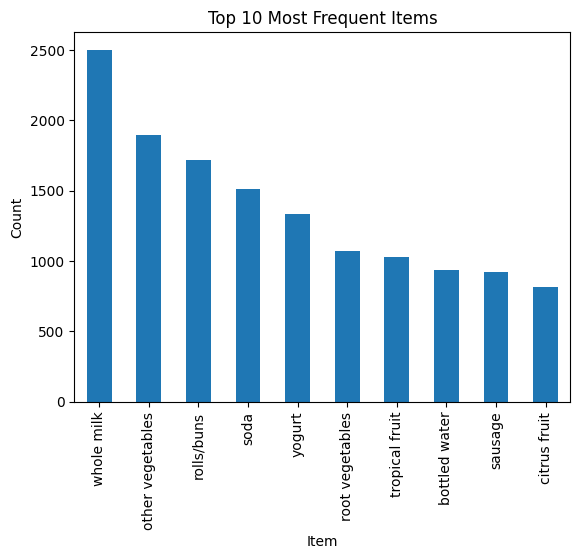

In [14]:
df['itemDescription'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Most Frequent Items')
plt.xlabel('Item')
plt.ylabel('Count')
plt.show()

In [ ]:
# Number of baskets (transactions): 5     Number of unique items: 167

# Rule with the highest lift:  {whole milk, yogurt} → {sausage} (lift = 2.182917)

# The single most frequently bought item: whole milk

# One rule whose high confidence is explained by popularity rather than real association: 
# {sausage, yogurt} → {whole milk}   (confidence = 0.255814)